# Reference Time Drift Analysis across 2022 Runs

This notebook analyzes both the **DS reference time distribution** (^{\mathrm{DS}}$,  histogram) and the **SciFi reference time distribution** (^{\mathrm{SF}}$,  histogram) across all available 2022 runs in .

### Objectives:
1. Superimpose the ^{\mathrm{DS}}$ and ^{\mathrm{SF}}$ distributions for all available Category I and Category II runs with color encoding by run number.
2. Characterize the LHC bunch timing structure and monitor clock phase drifts across runs.
3. Quantify the fraction of accepted muon events for the 3 run-dependent Category I selection windows.


In [18]:
import os
import pandas as pd
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import uproot
import ddfUtils.mpl_styling as dms

# Prevent JupyROOT RCanvas crash in notebook environments
try:
    import ROOT
    ROOT.gROOT.SetBatch(True)
    import ROOT._jupyroot.helpers.utils as jutils
    jutils.RCanvasAvailable = lambda: False
except Exception:
    pass

# Set default font and style
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "figure.titlesize": 16,
})
print("Environment and libraries initialized successfully.")


Environment and libraries initialized successfully.


In [19]:
import os
import glob
import uproot
import numpy as np
from concurrent.futures import ThreadPoolExecutor

# ------------------------------------------------------------------------------
# Load reference time distributions from merged run files or single ROOT file
# Directory structure:
#   Runs dir:       /eos/user/i/idioniso/Timing/ref_times/runs/run<RUN>.root
#   Partitions dir: /eos/user/i/idioniso/Timing/ref_times_parts/<cat>/run<RUN>
# Single ROOT file fallback:
#   /eos/user/i/idioniso/Timing/reference_times_2022.root
# ------------------------------------------------------------------------------
runs_dir = "/eos/user/i/idioniso/Timing/ref_times/runs"
parts_dir = "/eos/user/i/idioniso/Timing/ref_times_parts"
ref_root_path = "/eos/user/i/idioniso/Timing/reference_times_2022.root"

def load_category_runs(hist_name="reft-DS", min_entries=50):
    """Load reference time distributions for catI and catII."""
    data_by_cat = {"catI": [], "catII": []}
    
    # 1. Try loading from individual run ROOT files via category partition folders
    if os.path.exists(runs_dir) and os.path.exists(parts_dir):
        def _load_run(task):
            rdir, cat = task
            try:
                rnum = int(rdir.replace("run00", "").replace("run0", "").replace("run", ""))
            except ValueError:
                return None
            rfile = os.path.join(runs_dir, f"{rdir}.root")
            if not os.path.exists(rfile):
                return None
            try:
                with uproot.open(rfile) as f:
                    if hist_name not in f:
                        return None
                    counts, edges = f[hist_name].to_numpy()
                    total = counts.sum()
                    if total < min_entries:
                        return None
                    centers = 0.5 * (edges[:-1] + edges[1:])
                    mode_idx = np.argmax(counts)
                    peak_val = counts[mode_idx]
                    return {
                        "cat": cat,
                        "run": rnum,
                        "edges": edges,
                        "centers": centers,
                        "counts": counts,
                        "norm_peak": counts / peak_val if peak_val > 0 else counts,
                        "norm_area": counts / total if total > 0 else counts,
                        "total": total,
                        "mode_t": centers[mode_idx],
                        "peak_val": peak_val,
                        "mode_err": 0.5 * (edges[1] - edges[0]),
                    }
            except Exception:
                return None

        tasks = []
        for cat in ["catI", "catII"]:
            cat_parts = os.path.join(parts_dir, cat)
            if os.path.exists(cat_parts):
                for rdir in sorted(os.listdir(cat_parts)):
                    if rdir.startswith("run"):
                        tasks.append((rdir, cat))

        with ThreadPoolExecutor(max_workers=16) as pool:
            results = list(pool.map(_load_run, tasks))

        for r in results:
            if r is not None:
                data_by_cat[r["cat"]].append(r)

    # 2. Fallback to consolidated single ROOT file if runs directory was empty
    if not data_by_cat["catI"] and not data_by_cat["catII"] and os.path.exists(ref_root_path):
        with uproot.open(ref_root_path) as f:
            for cat in ["catI", "catII"]:
                if cat not in f:
                    continue
                cat_dir = f[cat]
                for run_key in cat_dir.keys(cycle=False):
                    try:
                        rnum = int(run_key.replace("run00", "").replace("run0", "").replace("run", ""))
                    except ValueError:
                        continue
                    full_hpath = f"{cat}/{run_key}/{hist_name}"
                    if full_hpath not in f:
                        continue
                    counts, edges = f[full_hpath].to_numpy()
                    total = counts.sum()
                    if total < min_entries:
                        continue
                    centers = 0.5 * (edges[:-1] + edges[1:])
                    mode_idx = np.argmax(counts)
                    peak_val = counts[mode_idx]
                    data_by_cat[cat].append({
                        "cat": cat,
                        "run": rnum,
                        "edges": edges,
                        "centers": centers,
                        "counts": counts,
                        "norm_peak": counts / peak_val if peak_val > 0 else counts,
                        "norm_area": counts / total if total > 0 else counts,
                        "total": total,
                        "mode_t": centers[mode_idx],
                        "peak_val": peak_val,
                        "mode_err": 0.5 * (edges[1] - edges[0]),
                    })

    for cat in ["catI", "catII"]:
        data_by_cat[cat].sort(key=lambda d: d["run"])
        print(f"Loaded {len(data_by_cat[cat])} runs for {cat} ({hist_name}).")
        if data_by_cat[cat]:
            print(f"  -> {cat} run range: {data_by_cat[cat][0]['run']} to {data_by_cat[cat][-1]['run']}")

    return data_by_cat

# Load DS reference time distributions for Cat I and Cat II
runs_by_cat_ds = load_category_runs(hist_name="reft-DS")
runs_data_catI = runs_by_cat_ds["catI"]
runs_data_catII = runs_by_cat_ds["catII"]
runs_data = runs_data_catI
runs = [d["run"] for d in runs_data]

# Load SciFi reference time distributions for Cat I and Cat II
runs_by_cat_sf = load_category_runs(hist_name="reft-SF")
runs_sf_catI = runs_by_cat_sf["catI"]
runs_sf_catII = runs_by_cat_sf["catII"]


Loaded 88 runs for catI (reft-DS).
  -> catI run range: 4427 to 5180
Loaded 30 runs for catII (reft-DS).
  -> catII run range: 5119 to 5408
Loaded 88 runs for catI (reft-SF).
  -> catI run range: 4427 to 5180
Loaded 30 runs for catII (reft-SF).
  -> catII run range: 5119 to 5408


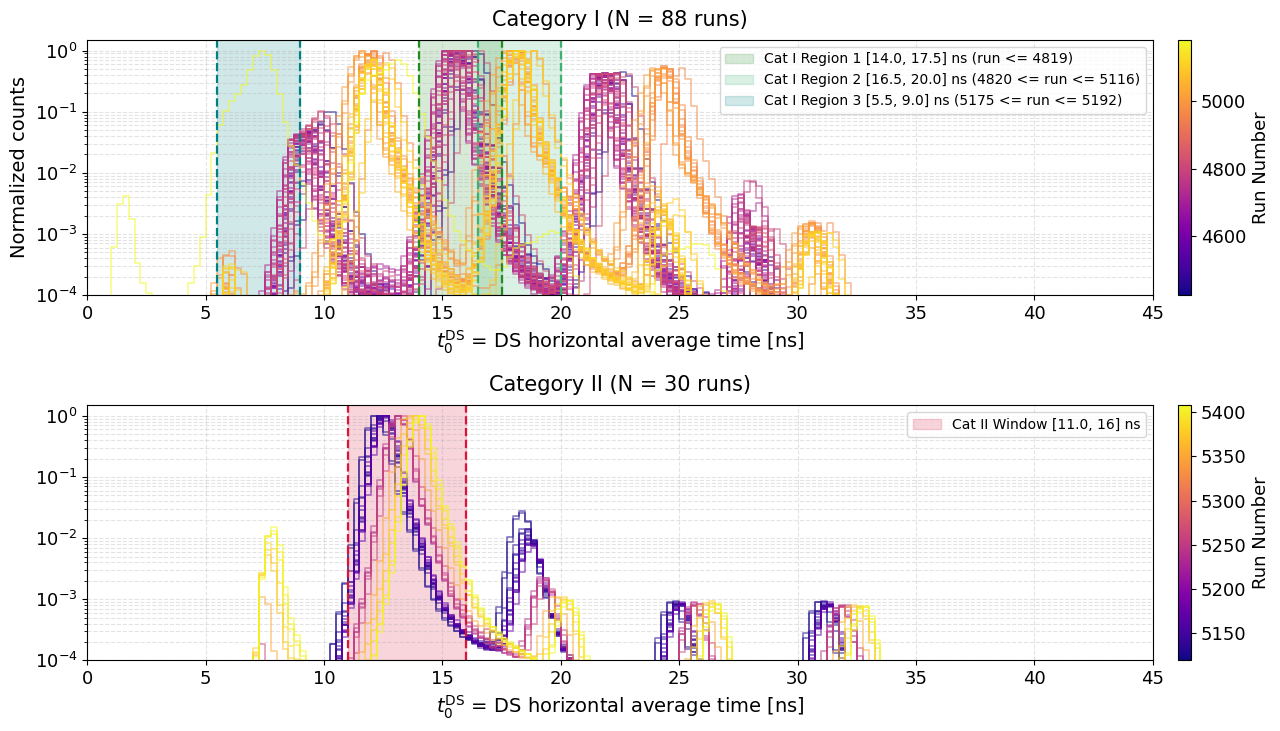

In [26]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharey=True)

# Define Category I run-dependent reference windows
catI_windows = [
    ("Cat I Region 1 [14.0, 17.5] ns (run <= 4819)", 14.0, 17.5, "forestgreen"),
    ("Cat I Region 2 [16.5, 20.0] ns (4820 <= run <= 5116)", 16.5, 20.0, "mediumseagreen"),
    ("Cat I Region 3 [5.5, 9.0] ns (5175 <= run <= 5192)", 5.5, 9.0, "teal"),
]

# Define Category II reference window
catII_windows = [
    ("Cat II Window [11.0, 16] ns", 11.0, 16.0, "crimson")
]

panels = [
    ("Category I", runs_data_catI, axes[0], cm.plasma, catI_windows),
    ("Category II", runs_data_catII, axes[1], cm.plasma, catII_windows)
]

for title, rdata, ax, cmap, windows in panels:
    if not rdata:
        ax.text(0.5, 0.5, f"No runs loaded for {title}", transform=ax.transAxes,
                ha="center", va="center", fontsize=14, color="gray")
        ax.set_title(title, fontsize=15, pad=10)
        ax.set_xlabel(r"$t_0^{\mathrm{DS}}$ = DS horizontal average time [ns]", fontsize=14)
        ax.grid(True, which="both", linestyle="--", alpha=0.35)
        continue

    run_numbers = [d["run"] for d in rdata]
    min_run, max_run = min(run_numbers), max(run_numbers)
    norm = mcolors.Normalize(vmin=min_run, vmax=max(max_run, min_run + 1))

    # Plot each run with color mapped to run number
    for d in rdata:
        color = cmap(norm(d["run"]))
        ax.step(d["edges"][:-1], d["norm_peak"], where="post", color=color, alpha=0.55, lw=1.2)

    # Shaded reference windows
    for w_label, w_low, w_high, w_col in windows:
        ax.axvspan(w_low, w_high, color=w_col, alpha=0.18, label=w_label)
        ax.axvline(w_low, color=w_col, linestyle="--", lw=1.6)
        ax.axvline(w_high, color=w_col, linestyle="--", lw=1.6)

    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1.5)
    ax.set_xlim(0, 45)
    ax.set_xlabel(r"$t_0^{\mathrm{DS}}$ = DS horizontal average time [ns]", fontsize=14)
    ax.set_title(f"{title} (N = {len(rdata)} runs)", fontsize=15, pad=10)
    ax.grid(True, which="both", linestyle="--", alpha=0.35)

    # Individual colorbar per panel
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Run Number", fontsize=13)

    ax.legend(loc="upper right", frameon=True, fontsize=10)

axes[0].set_ylabel("Normalized counts", fontsize=14)

plt.tight_layout()
plt.show()


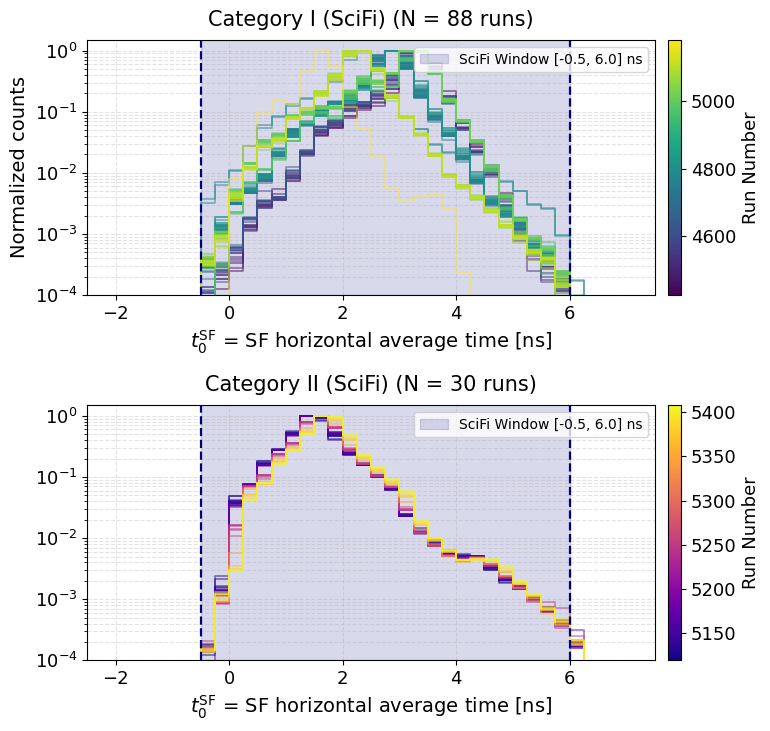

In [33]:
# SciFi Reference Time Distributions (t0^SF) for Category I and Category II
fig, axes = plt.subplots(2, 1, figsize=(8, 7.5), sharey=True)

# SciFi reference window [-0.5, 6.0] ns
sf_window = [("SciFi Window [-0.5, 6.0] ns", -0.5, 6.0, "navy")]

panels_sf = [
    ("Category I (SciFi)", runs_sf_catI, axes[0], cm.viridis, sf_window),
    ("Category II (SciFi)", runs_sf_catII, axes[1], cm.plasma, sf_window)
]

for title, rdata, ax, cmap, windows in panels_sf:
    if not rdata:
        ax.text(0.5, 0.5, f"No runs loaded for {title}", transform=ax.transAxes,
                ha="center", va="center", fontsize=14, color="gray")
        ax.set_title(title, fontsize=15, pad=10)
        ax.set_xlabel(r"t^{SF}_0$ = SciFi average time [ns]", fontsize=14)
        ax.grid(True, which="both", linestyle="--", alpha=0.35)
        continue

    run_numbers = [d["run"] for d in rdata]
    min_run, max_run = min(run_numbers), max(run_numbers)
    norm = mcolors.Normalize(vmin=min_run, vmax=max(max_run, min_run + 1))

    # Plot each run with color mapped to run number
    for d in rdata:
        color = cmap(norm(d["run"]))
        ax.step(d["edges"][:-1], d["norm_peak"], where="post", color=color, alpha=0.55, lw=1.2)

    # Shaded reference windows
    for w_label, w_low, w_high, w_col in windows:
        ax.axvspan(w_low, w_high, color=w_col, alpha=0.15, label=w_label)
        ax.axvline(w_low, color=w_col, linestyle="--", lw=1.6)
        ax.axvline(w_high, color=w_col, linestyle="--", lw=1.6)

    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1.5)
    ax.set_xlim(-2.5, 7.5)
    ax.set_xlabel(r"$t_0^{\mathrm{SF}}$ = SF horizontal average time [ns]", fontsize=14)
    ax.set_title(f"{title} (N = {len(rdata)} runs)", fontsize=15, pad=10)
    ax.grid(True, which="both", linestyle="--", alpha=0.35)

    # Individual colorbar per panel
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Run Number", fontsize=13)

    ax.legend(loc="upper right", frameon=True, fontsize=10)

axes[0].set_ylabel("Normalized counts", fontsize=14)

plt.tight_layout()
plt.show()


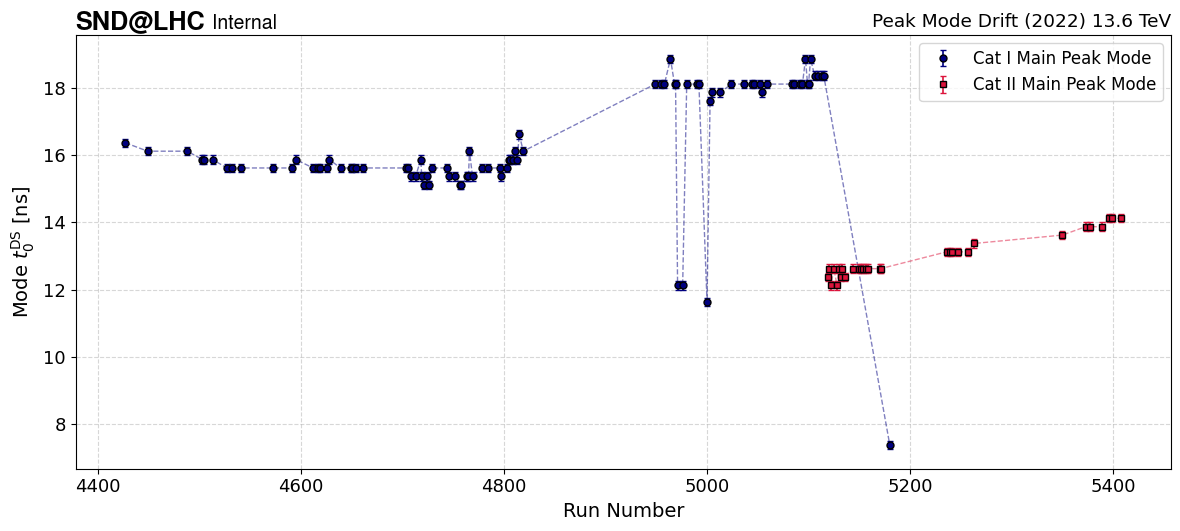

In [22]:
fig, ax = plt.subplots(figsize=(12, 5.5))

if runs_data_catI:
    runs_I = [d["run"] for d in runs_data_catI]
    modes_I = [d["mode_t"] for d in runs_data_catI]
    mode_errs_I = [d["mode_err"] for d in runs_data_catI]
    ax.errorbar(runs_I, modes_I, yerr=mode_errs_I, fmt="o", color="navy", ecolor="navy",
                elinewidth=1.2, capsize=2.5, markersize=5, markeredgecolor="black",
                zorder=3, label="Cat I Main Peak Mode")
    ax.plot(runs_I, modes_I, color="navy", linestyle="--", alpha=0.5, lw=1)

if runs_data_catII:
    runs_II = [d["run"] for d in runs_data_catII]
    modes_II = [d["mode_t"] for d in runs_data_catII]
    mode_errs_II = [d["mode_err"] for d in runs_data_catII]
    ax.errorbar(runs_II, modes_II, yerr=mode_errs_II, fmt="s", color="crimson", ecolor="crimson",
                elinewidth=1.2, capsize=2.5, markersize=5, markeredgecolor="black",
                zorder=3, label="Cat II Main Peak Mode")
    ax.plot(runs_II, modes_II, color="crimson", linestyle="--", alpha=0.5, lw=1)

ax.set_xlabel("Run Number", fontsize=14)
ax.set_ylabel(r"Mode $t_0^{\mathrm{DS}}$ [ns]", fontsize=14)
ax.grid(True, linestyle="--", alpha=0.5)

dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Peak Mode Drift (2022)", ax=ax)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()


In [ ]:
# Compare event acceptance for Category-I run-dependent windows vs old hardcoded [19.5, 24.5] window
def get_catI_window(run_nr):
    """Returns the (t_min, t_max) reference selection window for Category I runs."""
    if run_nr <= 4819:
        return 14.0, 17.5
    elif run_nr <= 5116:
        return 16.5, 20.0
    elif 5175 <= run_nr <= 5192:
        return 5.5, 9.0
    return 14.0, 17.5

def get_acceptance(d, t_min, t_max):
    mask = (d["centers"] >= t_min) & (d["centers"] <= t_max)
    return 100.0 * d["counts"][mask].sum() / d["total"]

acc_dynamic_catI = [get_acceptance(d, *get_catI_window(d["run"])) for d in runs_data_catI]
acc_old_hardcoded = [get_acceptance(d, 19.5, 24.5) for d in runs_data_catI]

runs_I = [d["run"] for d in runs_data_catI]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(runs_I, acc_dynamic_catI, marker="o", color="forestgreen", lw=1.8, label=r"Category I Run-Dependent Windows (3 Regions)")
ax.plot(runs_I, acc_old_hardcoded, marker="s", color="crimson", lw=1.8, label=r"Old Static Window $[19.5, 24.5]$ ns")

ax.set_xlabel("Run Number", fontsize=14)
ax.set_ylabel("Accepted Events [%]", fontsize=14)
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.5)

dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Event Selection Acceptance (Cat I)", ax=ax)

ax.legend(loc="center right", frameon=True)
plt.tight_layout()
plt.show()

mean_dyn = np.mean(acc_dynamic_catI)
min_dyn, max_dyn = np.min(acc_dynamic_catI), np.max(acc_dynamic_catI)
mean_old = np.mean(acc_old_hardcoded)
min_old, max_old = np.min(acc_old_hardcoded), np.max(acc_old_hardcoded)

print(f"Mean acceptance with Run-Dependent 3-Region windows: {mean_dyn:.1f}% (min: {min_dyn:.1f}%, max: {max_dyn:.1f}%)")
print(f"Mean acceptance with Old Static [19.5, 24.5] window: {mean_old:.1f}% (min: {min_old:.1f}%, max: {max_old:.1f}%)")


---
# Calibration Constants Drift Analysis

This section analyzes whether the timing calibration constants drift across 2022 runs or remain stable.
It examines:
1. **$c_{\mathrm{scint}}$** (effective signal speed in scintillator, cm/ns)
2. **Fine Alignment Offsets** (relative channel-to-channel time alignment, ns)
3. **Time-Walk Parameters** ($t_0$ and $\alpha$ / shape terms)

Constants are parsed from `/eos/user/i/idioniso/Timing/run<runNr>/run<runNr>_timing_calibration.json`.

In [ ]:
# Load consolidated calibration constants for the selected Category I runs
calib_runs = []

for rd in run_dirs:
    bname = os.path.basename(rd)
    try:
        rnum = int(bname.replace("run00", "").replace("run0", "").replace("run", ""))
    except ValueError:
        continue
    
    if selected_runs_set is not None and rnum not in selected_runs_set:
        continue
        
    calib_json = os.path.join(rd, f"{bname}_timing_calibration.json")
    if not os.path.exists(calib_json):
        continue
        
    with open(calib_json) as jf:
        cdata = json.load(jf)
    
    # Extract SF summary statistics
    sf_cscint_dict = cdata.get("SF", {}).get("cscint", {})
    sf_align_dict = cdata.get("SF", {}).get("alignment", {})
    sf_tw_dict = cdata.get("SF", {}).get("timewalk", {})
    
    cscint_vals = [v[0] for v in sf_cscint_dict.values() if isinstance(v, list) and len(v) >= 1]
    align_vals = [v[0] for v in sf_align_dict.values() if isinstance(v, list) and len(v) >= 1]
    tw_t0_vals = [v["t0"] for v in sf_tw_dict.values() if isinstance(v, dict) and "t0" in v]
    tw_alpha_vals = [v["alpha"] for v in sf_tw_dict.values() if isinstance(v, dict) and "alpha" in v]
    
    n_c = len(cscint_vals)
    n_a = len(align_vals)
    n_tw = len(tw_t0_vals)
    
    calib_runs.append({
        "run": rnum,
        "cat": "I",
        "sf_cscint": sf_cscint_dict,
        "sf_align": sf_align_dict,
        "sf_tw": sf_tw_dict,
        "cscint_mean": np.mean(cscint_vals) if n_c else np.nan,
        "cscint_std": np.std(cscint_vals) if n_c else np.nan,
        "cscint_sem": np.std(cscint_vals) / np.sqrt(n_c) if n_c else np.nan,
        "align_mean": np.mean(align_vals) if n_a else np.nan,
        "align_std": np.std(align_vals) if n_a else np.nan,
        "align_sem": np.std(align_vals) / np.sqrt(n_a) if n_a else np.nan,
        "tw_t0_mean": np.mean(tw_t0_vals) if n_tw else np.nan,
        "tw_t0_std": np.std(tw_t0_vals) if n_tw else np.nan,
        "tw_t0_sem": np.std(tw_t0_vals) / np.sqrt(n_tw) if n_tw else np.nan,
        "tw_alpha_mean": np.mean(tw_alpha_vals) if n_tw else np.nan,
        "tw_alpha_std": np.std(tw_alpha_vals) if n_tw else np.nan,
        "tw_alpha_sem": np.std(tw_alpha_vals) / np.sqrt(n_tw) if n_tw else np.nan,
        "n_cscint": n_c,
        "n_align": n_a,
        "n_tw": n_tw,
    })

calib_runs.sort(key=lambda x: x["run"])
print(f"Loaded calibration constants for {len(calib_runs)} filtered Category I runs (Runs {calib_runs[0]['run']} -> {calib_runs[-1]['run']}).")


In [ ]:
# Plot global SF parameters drift across runs
# Note: Error bars represent the Standard Error of the Mean (SEM = std / sqrt(N))
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

runs_arr = [c["run"] for c in calib_runs]
cats_arr = [c["cat"] for c in calib_runs]

# 1. c_scint drift
ax = axes[0]
cscint_means = [c["cscint_mean"] for c in calib_runs]
cscint_sems = [c["cscint_sem"] for c in calib_runs]
ax.errorbar(runs_arr, cscint_means, yerr=cscint_sems, fmt="o", color="steelblue", ecolor="steelblue", elinewidth=1.2, capsize=2, ms=5, label=r"Mean $c_{\mathrm{scint}}$ (SF channels, error: $\sigma_{\bar{x}}$)")
ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]")
ax.set_ylim(13.5, 15.5)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")
dms.add_label(ax=ax, mainText="SND@LHC", extraText="Preliminary")

# 2. Fine Alignment offset drift
ax = axes[1]
align_means = [c["align_mean"] for c in calib_runs]
align_sems = [c["align_sem"] for c in calib_runs]
ax.errorbar(runs_arr, align_means, yerr=align_sems, fmt="s", color="darkorange", ecolor="darkorange", elinewidth=1.2, capsize=2, ms=5, label=r"Mean Alignment Offset (SF, error: $\sigma_{\bar{x}}$)")
ax.set_ylabel(r"Alignment Offset [ns]")
ax.set_ylim(-11.0, -8.0)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

# 3. Time-Walk t0 drift
ax = axes[2]
tw_t0_means = [c["tw_t0_mean"] for c in calib_runs]
tw_t0_sems = [c["tw_t0_sem"] for c in calib_runs]
ax.errorbar(runs_arr, tw_t0_means, yerr=tw_t0_sems, fmt="^", color="forestgreen", ecolor="forestgreen", elinewidth=1.2, capsize=2, ms=5, label=r"Mean TW $t_0$ (SF, error: $\sigma_{\bar{x}}$)")
ax.set_xlabel("Run Number")
ax.set_ylabel(r"Time-Walk $t_0$ [ns]")
ax.set_ylim(-11.0, -8.0)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


In [ ]:
# Track drift of specific key SciFi channels across runs
# Channel format: <detector_element_id>_<sipm_channel>
sample_channels = ["20001_0", "20002_0", "20003_0", "20004_0"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Left: c_scint per channel
ax = axes[0]
for ch in sample_channels:
    r_list, c_list, c_err = [], [], []
    for cr in calib_runs:
        if ch in cr["sf_cscint"]:
            v = cr["sf_cscint"][ch]
            if isinstance(v, list) and len(v) >= 2:
                r_list.append(cr["run"])
                c_list.append(v[0])
                c_err.append(v[1])
    if r_list:
        ax.errorbar(r_list, c_list, yerr=c_err, fmt="o-", ms=4, lw=1.2, label=f"Ch {ch}")

ax.set_xlabel("Run Number")
ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]")
ax.set_title(r"Speed of Light Stability ($c_{\mathrm{scint}}$)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="best", framealpha=0.8)
dms.add_label(ax=ax, mainText="SND@LHC", extraText="Preliminary")

# Right: Alignment offset per channel
ax = axes[1]
for ch in sample_channels:
    r_list, a_list, a_err = [], [], []
    for cr in calib_runs:
        if ch in cr["sf_align"]:
            v = cr["sf_align"][ch]
            if isinstance(v, list) and len(v) >= 2:
                r_list.append(cr["run"])
                a_list.append(v[0])
                a_err.append(v[1])
    if r_list:
        ax.errorbar(r_list, a_list, yerr=a_err, fmt="s-", ms=4, lw=1.2, label=f"Ch {ch}")

ax.set_xlabel("Run Number")
ax.set_ylabel(r"Alignment Offset [ns]")
ax.set_title("Fine Alignment Stability")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="best", framealpha=0.8)
dms.add_label(ax=ax, mainText="SND@LHC", extraText="Preliminary")

plt.tight_layout()
plt.show()


In [ ]:
# Distribution of c_scint across all channels per run
fig, ax = plt.subplots(figsize=(12, 6))

box_data = []
box_labels = []
# Sample every 3rd run to keep boxplot readable
sampled_runs = calib_runs[::3]

for cr in sampled_runs:
    vals = [v[0] for v in cr["sf_cscint"].values() if isinstance(v, list) and len(v) >= 1]
    if vals:
        box_data.append(vals)
        box_labels.append(str(cr["run"]))

bp = ax.boxplot(box_data, tick_labels=box_labels, patch_artist=True, showfliers=False,
                medianprops=dict(color="red", linewidth=1.5))

for patch in bp["boxes"]:
    patch.set_facecolor("lightblue")
    patch.set_alpha(0.7)

ax.set_xlabel("Run Number (sampled)")
ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]")
ax.set_title(r"$c_{\mathrm{scint}}$ Channel Spread across Runs")
plt.xticks(rotation=45, ha="right")
ax.grid(True, linestyle="--", alpha=0.5)
dms.add_label(ax=ax, mainText="SND@LHC", extraText="Preliminary")

plt.tight_layout()
plt.show()


---
# Category III Reference Time Drift Analysis (2023 - 2026)

This section analyzes the reference time distributions for **Category III runs** across LHC Run 3 years:
* **2023**: Runs in 
* **2024**: Runs in 
* **2025**: Runs in 
* **2026**: Runs in 


In [ ]:
# Load Category III runs partitioned by year (2023, 2024, 2025, 2026)
repo_root = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
year_runs_map = {}
for y in [2023, 2024, 2025, 2026]:
    csv_path = os.path.join(repo_root, f"runs_{y}.csv")
    if not os.path.exists(csv_path):
        csv_path = f"runs_{y}.csv"
    if os.path.exists(csv_path):
        df_y = pd.read_csv(csv_path)
        year_runs_map[y] = set(df_y["run_number"].astype(int))
    else:
        year_runs_map[y] = set()

def load_catIII_runs(hist_name="reft-DS", min_entries=50):
    """Load Category III runs grouped by LHC Run 3 year."""
    data_by_year = {y: [] for y in [2023, 2024, 2025, 2026]}
    cat3_parts = os.path.join(parts_dir, "catIII")
    
    if os.path.exists(runs_dir) and os.path.exists(cat3_parts):
        def _load_run(rdir):
            try:
                rnum = int(rdir.replace("run00", "").replace("run0", "").replace("run", ""))
            except ValueError:
                return None
            rfile = os.path.join(runs_dir, f"{rdir}.root")
            if not os.path.exists(rfile):
                return None
            try:
                with uproot.open(rfile) as f:
                    if hist_name not in f:
                        return None
                    counts, edges = f[hist_name].to_numpy()
                    total = counts.sum()
                    if total < min_entries:
                        return None
                    centers = 0.5 * (edges[:-1] + edges[1:])
                    mode_idx = np.argmax(counts)
                    peak_val = counts[mode_idx]
                    
                    ryear = None
                    for y, rset in year_runs_map.items():
                        if rnum in rset:
                            ryear = y
                            break
                    return {
                        "run": rnum,
                        "year": ryear,
                        "edges": edges,
                        "centers": centers,
                        "counts": counts,
                        "norm_peak": counts / peak_val if peak_val > 0 else counts,
                        "norm_area": counts / total if total > 0 else counts,
                        "total": total,
                        "mode_t": centers[mode_idx],
                        "peak_val": peak_val,
                        "mode_err": 0.5 * (edges[1] - edges[0]),
                    }
            except Exception:
                return None

        rdirs = sorted([d for d in os.listdir(cat3_parts) if d.startswith("run")])
        with ThreadPoolExecutor(max_workers=16) as pool:
            results = list(pool.map(_load_run, rdirs))

        for r in results:
            if r is not None and r["year"] in data_by_year:
                data_by_year[r["year"]].append(r)

    for y in [2023, 2024, 2025, 2026]:
        data_by_year[y].sort(key=lambda d: d["run"])
        print(f"Loaded {len(data_by_year[y])} Category III runs for Year {y} ({hist_name}).")
        if data_by_year[y]:
            print(f"  -> {y} run range: {data_by_year[y][0]['run']} to {data_by_year[y][-1]['run']}")

    return data_by_year

runs_catIII_ds = load_catIII_runs(hist_name="reft-DS")
runs_catIII_sf = load_catIII_runs(hist_name="reft-SF")


In [ ]:
# Plot DS reference time distributions (t0^DS) for Category III by Year (2023 - 2026)
fig, axes = plt.subplots(2, 2, figsize=(18, 14), sharey=True)
axes_flat = axes.flatten()

year_cmaps = {
    2023: cm.viridis,
    2024: cm.plasma,
    2025: cm.inferno,
    2026: cm.magma,
}

# Category III reference window [18.5, 20.5] ns
catIII_window = [("Cat III Window [11.0, 23.5] ns", 11.0, 23.5, "forestgreen")]

for idx, y in enumerate([2023, 2024, 2025, 2026]):
    ax = axes_flat[idx]
    rdata = runs_catIII_ds[y]
    cmap = year_cmaps[y]
    title = f"Category III - Year {y}"
    
    if not rdata:
        ax.text(0.5, 0.5, f"No Category III runs available for {y}", transform=ax.transAxes,
                ha="center", va="center", fontsize=14, color="gray")
        ax.set_title(title, fontsize=15, pad=10)
        ax.set_xlabel(r"^{\mathrm{DS}}$ = DS horizontal average time [ns]", fontsize=14)
        ax.grid(True, which="both", linestyle="--", alpha=0.35)
        continue

    run_numbers = [d["run"] for d in rdata]
    min_run, max_run = min(run_numbers), max(run_numbers)
    norm = mcolors.Normalize(vmin=min_run, vmax=max(max_run, min_run + 1))

    for d in rdata:
        color = cmap(norm(d["run"]))
        ax.step(d["edges"][:-1], d["norm_peak"], where="post", color=color, alpha=0.55, lw=1.2)

    for w_label, w_low, w_high, w_col in catIII_window:
        ax.axvspan(w_low, w_high, color=w_col, alpha=0.18, label=w_label)
        ax.axvline(w_low, color=w_col, linestyle="--", lw=1.6)
        ax.axvline(w_high, color=w_col, linestyle="--", lw=1.6)

    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1.5)
    ax.set_xlim(0, 45)
    ax.set_xlabel(r"^{\mathrm{DS}}$ = DS horizontal average time [ns]", fontsize=14)
    ax.set_title(f"{title} (N = {len(rdata)} runs)", fontsize=15, pad=10)
    ax.grid(True, which="both", linestyle="--", alpha=0.35)

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label(f"Run Number ({y})", fontsize=13)

    ax.legend(loc="upper right", frameon=True, fontsize=10)

axes_flat[0].set_ylabel("Normalized counts (peak = 1.0)", fontsize=14)
axes_flat[2].set_ylabel("Normalized counts (peak = 1.0)", fontsize=14)

dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Category III Reference Time Distributions (2023-2026)", ax=axes_flat[0])

plt.tight_layout()
plt.show()


In [ ]:
# Plot SciFi reference time distributions (t0^SF) for Category III by Year (2023 - 2026)
fig, axes = plt.subplots(2, 2, figsize=(18, 14), sharey=True)
axes_flat = axes.flatten()

sf_window = [("SciFi Window [-0.5, 6.0] ns", -0.5, 6.0, "navy")]

for idx, y in enumerate([2023, 2024, 2025, 2026]):
    ax = axes_flat[idx]
    rdata = runs_catIII_sf[y]
    cmap = year_cmaps[y]
    title = f"Category III SciFi - Year {y}"
    
    if not rdata:
        ax.text(0.5, 0.5, f"No Category III runs available for {y}", transform=ax.transAxes,
                ha="center", va="center", fontsize=14, color="gray")
        ax.set_title(title, fontsize=15, pad=10)
        ax.set_xlabel(r"^{\mathrm{SF}}$ = SciFi average time [ns]", fontsize=14)
        ax.grid(True, which="both", linestyle="--", alpha=0.35)
        continue

    run_numbers = [d["run"] for d in rdata]
    min_run, max_run = min(run_numbers), max(run_numbers)
    norm = mcolors.Normalize(vmin=min_run, vmax=max(max_run, min_run + 1))

    for d in rdata:
        color = cmap(norm(d["run"]))
        ax.step(d["edges"][:-1], d["norm_peak"], where="post", color=color, alpha=0.55, lw=1.2)

    for w_label, w_low, w_high, w_col in sf_window:
        ax.axvspan(w_low, w_high, color=w_col, alpha=0.15, label=w_label)
        ax.axvline(w_low, color=w_col, linestyle="--", lw=1.6)
        ax.axvline(w_high, color=w_col, linestyle="--", lw=1.6)

    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1.5)
    ax.set_xlim(-15, 25)
    ax.set_xlabel(r"^{\mathrm{SF}}$ = SciFi average time [ns]", fontsize=14)
    ax.set_title(f"{title} (N = {len(rdata)} runs)", fontsize=15, pad=10)
    ax.grid(True, which="both", linestyle="--", alpha=0.35)

    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label(f"Run Number ({y})", fontsize=13)

    ax.legend(loc="upper right", frameon=True, fontsize=10)

axes_flat[0].set_ylabel("Normalized counts (peak = 1.0)", fontsize=14)
axes_flat[2].set_ylabel("Normalized counts (peak = 1.0)", fontsize=14)

dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Category III SciFi Reference Time Distributions (2023-2026)", ax=axes_flat[0])

plt.tight_layout()
plt.show()


---
# Unified Category Distributions (Category II & Category III)

This section displays the consolidated distributions combining all runs per category:
* **Category II**: Merged over all 2022 Cat II runs with selection window $[11.0, 16.0]$ ns
* **Category III**: Merged over all 2023 - 2026 Cat III runs with selection window $[11.0, 23.5]$ ns


In [ ]:
# Plot Unified Category II and Category III distributions with their selection windows
cats_dir = "/eos/user/i/idioniso/Timing/ref_times/categories"

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

cat_specs = [
    ("Category II (Consolidated)", "catII", axes[0], "crimson", [("Cat II Window [11.0, 16.0] ns", 11.0, 16.0, "crimson")]),
    ("Category III (Consolidated)", "catIII", axes[1], "teal", [("Cat III Window [11.0, 23.5] ns", 11.0, 23.5, "teal")]),
]

for title, cat_name, ax, line_col, windows in cat_specs:
    cat_file = os.path.join(cats_dir, f"{cat_name}.root")
    if not os.path.exists(cat_file):
        ax.text(0.5, 0.5, f"{cat_file} not found", transform=ax.transAxes,
                ha="center", va="center", fontsize=14, color="gray")
        ax.set_title(title, fontsize=15, pad=10)
        ax.grid(True, which="both", linestyle="--", alpha=0.35)
        continue

    with uproot.open(cat_file) as f:
        counts, edges = f["reft-DS"].to_numpy()
        total = counts.sum()
        peak = counts.max()
        norm_peak = counts / peak if peak > 0 else counts

        # Step plot
        ax.step(edges[:-1], norm_peak, where="post", color=line_col, lw=2.0, label=f"{cat_name} Unified (N = {int(total):,} entries)")

        # Shaded reference windows
        for w_label, w_low, w_high, w_col in windows:
            mask = (edges[:-1] >= w_low) & (edges[:-1] <= w_high)
            acc = 100.0 * counts[mask].sum() / total if total > 0 else 0.0
            lbl = f"{w_label} ({acc:.1f}% acceptance)"
            ax.axvspan(w_low, w_high, color=w_col, alpha=0.18, label=lbl)
            ax.axvline(w_low, color=w_col, linestyle="--", lw=1.8)
            ax.axvline(w_high, color=w_col, linestyle="--", lw=1.8)

    ax.set_yscale("log")
    ax.set_ylim(1e-4, 1.5)
    ax.set_xlim(0, 45)
    ax.set_xlabel(r"$t_0^{\mathrm{DS}}$ = DS horizontal average time [ns]", fontsize=14)
    ax.set_title(title, fontsize=15, pad=10)
    ax.grid(True, which="both", linestyle="--", alpha=0.35)
    ax.legend(loc="upper right", frameon=True, fontsize=11)

axes[0].set_ylabel("Normalized counts (peak = 1.0)", fontsize=14)

# Add experiment label
dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="Consolidated Category Distributions", ax=axes[0])

plt.tight_layout()
plt.show()


---
# {\mathrm{scint}}$ Time-Dependence and Drift Across Runs

This section loads the fitted effective scintillator propagation speeds {\mathrm{scint}}$ extracted from the merged run files.
The linear regression mirrors the  fitting routine:
1. Slices the 2D ^{\mathrm{DS}} - t_{\mathrm{SiPM}}$ vs {\mathrm{pred}}$ distribution and fits Gaussian peaks to extract the MPV.
2. Performs a linear fit ($\text{pol1}$) to obtain the propagation slope  = \pm 1 / c_{\mathrm{scint}}$.
3. Evaluates the statistical fit error and systematic error (via 5 sub-segment fits).

The cells below visualize:
* **All SiPM channels together** across runs with a colormap indicating the SiPM channel index (bash..15$).
* **A single target SiPM channel** across runs plotted with its full error band ($\pm \sigma_{\text{tot}} = \sqrt{\sigma_{\text{fit}}^2 + \sigma_{\text{syst}}^2}$).


In [ ]:
# Load and plot c_scint across runs for all SiPM channels with colormap
import glob
import json

fits_dir = "/eos/user/i/idioniso/Timing/cscint/runs/fits"
# Also check if local output exists
if not os.path.exists(fits_dir):
    fits_dir = "/eos/user/i/idioniso/Timing/cscint/fits"

fit_files = sorted(glob.glob(os.path.join(fits_dir, "run*_cscint.json")))

# Structure: run_data[run_number] = { "DS": { ch: fit_dict }, "SF": { ch: fit_dict } }
runs_cscint_data = {}

for fpath in fit_files:
    bname = os.path.basename(fpath)
    rnum_str = bname.replace("_cscint.json", "").replace("run", "")
    try:
        rnum = int(rnum_str)
    except ValueError:
        continue
    with open(fpath) as jf:
        runs_cscint_data[rnum] = json.load(jf)

runs_sorted = sorted(runs_cscint_data.keys())
print(f"Loaded c_scint fits for {len(runs_sorted)} runs from {fits_dir}.")

# Plot all SiPM channels colored by SiPM index
fig, ax = plt.subplots(figsize=(14, 7))

cmap_sipm = cm.turbo
norm_sipm = mcolors.Normalize(vmin=0, vmax=15)

if runs_sorted:
    for rnum in runs_sorted:
        ds_channels = runs_cscint_data[rnum].get("DS", {})
        for ch_name, fit_res in ds_channels.items():
            sipm_idx = fit_res.get("sipm", int(ch_name.split("_")[1]))
            c_val = fit_res["c_scint"]
            col = cmap_sipm(norm_sipm(sipm_idx))
            ax.scatter(rnum, c_val, color=col, alpha=0.45, s=18, edgecolors="none")

    ax.set_xlabel("Run Number", fontsize=14)
    ax.set_ylabel(r"{\mathrm{scint}}$ [cm/ns]", fontsize=14)
    ax.set_ylim(8.0, 24.0)
    ax.grid(True, linestyle="--", alpha=0.4)

    sm = cm.ScalarMappable(norm=norm_sipm, cmap=cmap_sipm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("SiPM Index (0 = small, 1..15 = large/outer)", fontsize=13)
    cbar.set_ticks(range(0, 16, 2))

    dms.add_label(mainText="SND@LHC", extraText="Internal", suppText="All SiPM Channels c_scint Run-Dependence", ax=ax)
else:
    ax.text(0.5, 0.5, "No fit JSON files found yet.\nRun scripts/fit_cscint.py --input-dir /eos/user/i/idioniso/Timing/cscint/runs to generate.",
            ha="center", va="center", transform=ax.transAxes, fontsize=13, color="gray")
    ax.set_xlabel("Run Number", fontsize=14)
    ax.set_ylabel(r"{\mathrm{scint}}$ [cm/ns]", fontsize=14)

plt.tight_layout()
plt.show()


In [ ]:
# Plot time-dependence of c_scint for a single SiPM channel with statistical and total error bands
target_channel = "20002_6"  # Change this to any target channel e.g. "20001_4", "20002_6", etc.

runs_ch = []
c_vals = []
stat_errs = []
syst_errs = []
tot_errs = []

for rnum in runs_sorted:
    ds_channels = runs_cscint_data[rnum].get("DS", {})
    if target_channel in ds_channels:
        fit_d = ds_channels[target_channel]
        runs_ch.append(rnum)
        c_vals.append(fit_d["c_scint"])
        stat_errs.append(fit_d.get("delta_c_fit", 0.0))
        syst_errs.append(fit_d.get("delta_c_syst", 0.0))
        tot_errs.append(fit_d.get("delta_c_tot", np.sqrt(fit_d.get("delta_c_fit", 0)**2 + fit_d.get("delta_c_syst", 0)**2)))

fig, ax = plt.subplots(figsize=(13, 6))

if runs_ch:
    r_arr = np.array(runs_ch)
    c_arr = np.array(c_vals)
    stat_arr = np.array(stat_errs)
    tot_arr = np.array(tot_errs)

    # Shaded total error band (stat + syst in quadrature)
    ax.fill_between(r_arr, c_arr - tot_arr, c_arr + tot_arr, color="royalblue", alpha=0.22,
                    label=r"Total Uncertainty ($\pm \sqrt{\sigma_{\mathrm{fit}}^2 + \sigma_{\mathrm{syst}}^2}$)")

    # Error bars for statistical fit error
    ax.errorbar(r_arr, c_arr, yerr=stat_arr, fmt="o", color="navy", ecolor="navy",
                elinewidth=1.4, capsize=3, markersize=5, markeredgecolor="black", zorder=3,
                label=rf"Channel {target_channel} {{\mathrm{{scint}}}}$ ($\pm \sigma_{{\mathrm{{fit}}}}$)")

    # Horizontal mean guide
    w_mean = np.sum(c_arr / (tot_arr**2)) / np.sum(1.0 / (tot_arr**2))
    ax.axhline(w_mean, color="crimson", linestyle="--", lw=1.5, alpha=0.8,
               label=rf"Weighted Mean = {w_mean:.2f} cm/ns")

    ax.set_xlabel("Run Number", fontsize=14)
    ax.set_ylabel(r"{\mathrm{scint}}$ [cm/ns]", fontsize=14)
    ax.set_ylim(max(8.0, np.min(c_arr - tot_arr) - 1.0), min(22.0, np.max(c_arr + tot_arr) + 1.0))
    ax.grid(True, linestyle="--", alpha=0.45)
    ax.legend(loc="upper right", frameon=True, fontsize=11)

    dms.add_label(mainText="SND@LHC", extraText="Internal", suppText=f"Channel {target_channel} c_scint Drift", ax=ax)
else:
    ax.text(0.5, 0.5, f"No data found for channel {target_channel}",
            ha="center", va="center", transform=ax.transAxes, fontsize=13, color="gray")
    ax.set_xlabel("Run Number", fontsize=14)
    ax.set_ylabel(r"{\mathrm{scint}}$ [cm/ns]", fontsize=14)

plt.tight_layout()
plt.show()


In [ ]:
# Plot c_scint across all SiPM channels for a single selected run with error bars
selected_run = runs_sorted[0] if runs_sorted else 4427

fig, ax = plt.subplots(figsize=(15, 6.5))

if selected_run in runs_cscint_data:
    run_dict = runs_cscint_data[selected_run].get("DS", {})
    # Sort channels by detector ID and then SiPM index
    ch_keys = sorted(run_dict.keys(), key=lambda k: (int(k.split("_")[0]), int(k.split("_")[1])))
    
    x_indices = np.arange(len(ch_keys))
    c_vals = [run_dict[k]["c_scint"] for k in ch_keys]
    stat_errs = [run_dict[k].get("delta_c_fit", 0.0) for k in ch_keys]
    tot_errs = [run_dict[k].get("delta_c_tot", np.sqrt(run_dict[k].get("delta_c_fit", 0)**2 + run_dict[k].get("delta_c_syst", 0)**2)) for k in ch_keys]
    sipm_indices = [run_dict[k].get("sipm", int(k.split("_")[1])) for k in ch_keys]

    cmap_sipm = cm.turbo
    norm_sipm = mcolors.Normalize(vmin=0, vmax=15)
    colors = [cmap_sipm(norm_sipm(s)) for s in sipm_indices]

    # Total uncertainty (light error bar / cap)
    ax.errorbar(x_indices, c_vals, yerr=tot_errs, fmt="none", ecolor="lightsteelblue",
                elinewidth=2.5, capsize=3.5, capthick=1.2, zorder=2, label=r"Total Uncertainty ($\pm \sigma_{\mathrm{tot}}$)")

    # Statistical fit uncertainty (dark error bar)
    ax.errorbar(x_indices, c_vals, yerr=stat_errs, fmt="none", ecolor="navy",
                elinewidth=1.2, capsize=2, capthick=1.0, zorder=3, label=r"Fit Uncertainty ($\pm \sigma_{\mathrm{fit}}$)")

    # Scatter points colored by SiPM index
    scatter = ax.scatter(x_indices, c_vals, c=sipm_indices, cmap=cmap_sipm, norm=norm_sipm,
                         s=35, edgecolors="black", linewidths=0.6, zorder=4)

    # Reference mean line
    mean_val = np.mean(c_vals)
    ax.axhline(mean_val, color="crimson", linestyle="--", lw=1.5,
               label=rf"Mean $c_{{\mathrm{{scint}}}} = {mean_val:.2f}$ cm/ns")

    ax.set_xlabel("SiPM Channel Index", fontsize=14)
    ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]", fontsize=14)
    ax.set_ylim(8.0, 24.0)
    ax.grid(True, linestyle="--", alpha=0.45)
    ax.legend(loc="upper right", frameon=True, fontsize=11)

    cbar = fig.colorbar(scatter, ax=ax, pad=0.02)
    cbar.set_label("SiPM Index (0 = small, 1..15 = large/outer)", fontsize=13)
    cbar.set_ticks(range(0, 16, 2))

    dms.add_label(mainText="SND@LHC", extraText="Internal",
                  suppText=f"Run {selected_run}: $c_{{\mathrm{{scint}}}}$ for all SiPMs", ax=ax)
else:
    ax.text(0.5, 0.5, f"No fit data found for Run {selected_run}",
            ha="center", va="center", transform=ax.transAxes, fontsize=13, color="gray")
    ax.set_xlabel("SiPM Channel Index", fontsize=14)
    ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]", fontsize=14)

plt.tight_layout()
plt.show()
